This now uses srcB/dataprep.py
- difference : it passes lsit of horizons as dynamic list . so you dont have to open backend to modify the list.

In [1]:
import pandas as pd 
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")

### Data (GARCH avg version)

### Production of X_by_year (avg mfiv version)(versatile for all)


In [2]:
import pandas as pd
from pathlib import Path
DATA_DIR = Path("../data/rawData")
YEARS = [2019, 2020, 2021]
d_btc_raw_by_year = {}
df_raw_by_year = {}
for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y]    = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")


In [3]:
import sys
sys.path.insert(0 , "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")

In [4]:
for y in YEARS:
    d_btc_raw_by_year[y].index = pd.to_datetime(d_btc_raw_by_year[y].index)
    df_raw_by_year[y].index = pd.to_datetime(df_raw_by_year[y].index)

In [5]:
for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index("date_time")
    df_raw_by_year[y] = df_raw_by_year[y].set_index("date_time")

In [6]:
from srcB.ddout import derivative_data, datetime_to_timestamp, timestamp_to_datetime

In [7]:

### Data Prep
from srcB.dataPrep import dataprep
d_btc_by_year = {}
df_by_year = {}

for y in YEARS:
    d_btc = d_btc_raw_by_year[y]
    df    = df_raw_by_year[y]

    # prep = dataprep(d_btc=d_btc, df=df)
    # prep = dataprep(d_btc=d_btc, df=df, horizons=[3, 4, 10, 24])
    prep = dataprep(d_btc=d_btc, df=df, horizons=list(range(2, 577))) # save massive grid.
    d_btc_by_year[y], df_by_year[y] = prep.run_all()


In [8]:
d_btc_by_year[2021].columns

Index(['timestamp', 'open', 'high', 'low', 'Close', 'volume', 'cost', 'rfr',
       'r', 'F2',
       ...
       'F567', 'F568', 'F569', 'F570', 'F571', 'F572', 'F573', 'F574', 'F575',
       'F576'],
      dtype='str', length=584)

367 unique rfr values out of 8785
8749 unique 382 values out of 8785


<Axes: title={'center': 'rfr over 2021'}, xlabel='date_time'>

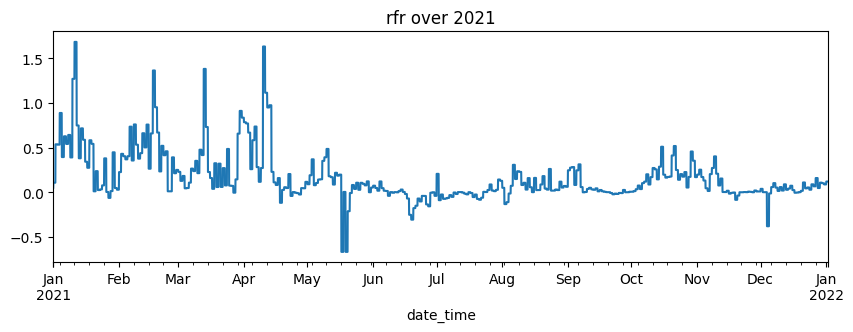

In [9]:
d_c = d_btc_by_year[2021]
print(d_c["rfr"].nunique(), "unique rfr values out of", len(d_c))
print(d_c["F382"].nunique(), "unique 382 values out of", len(d_c))
d_c["rfr"].plot(figsize=(10,3), title="rfr over 2021")

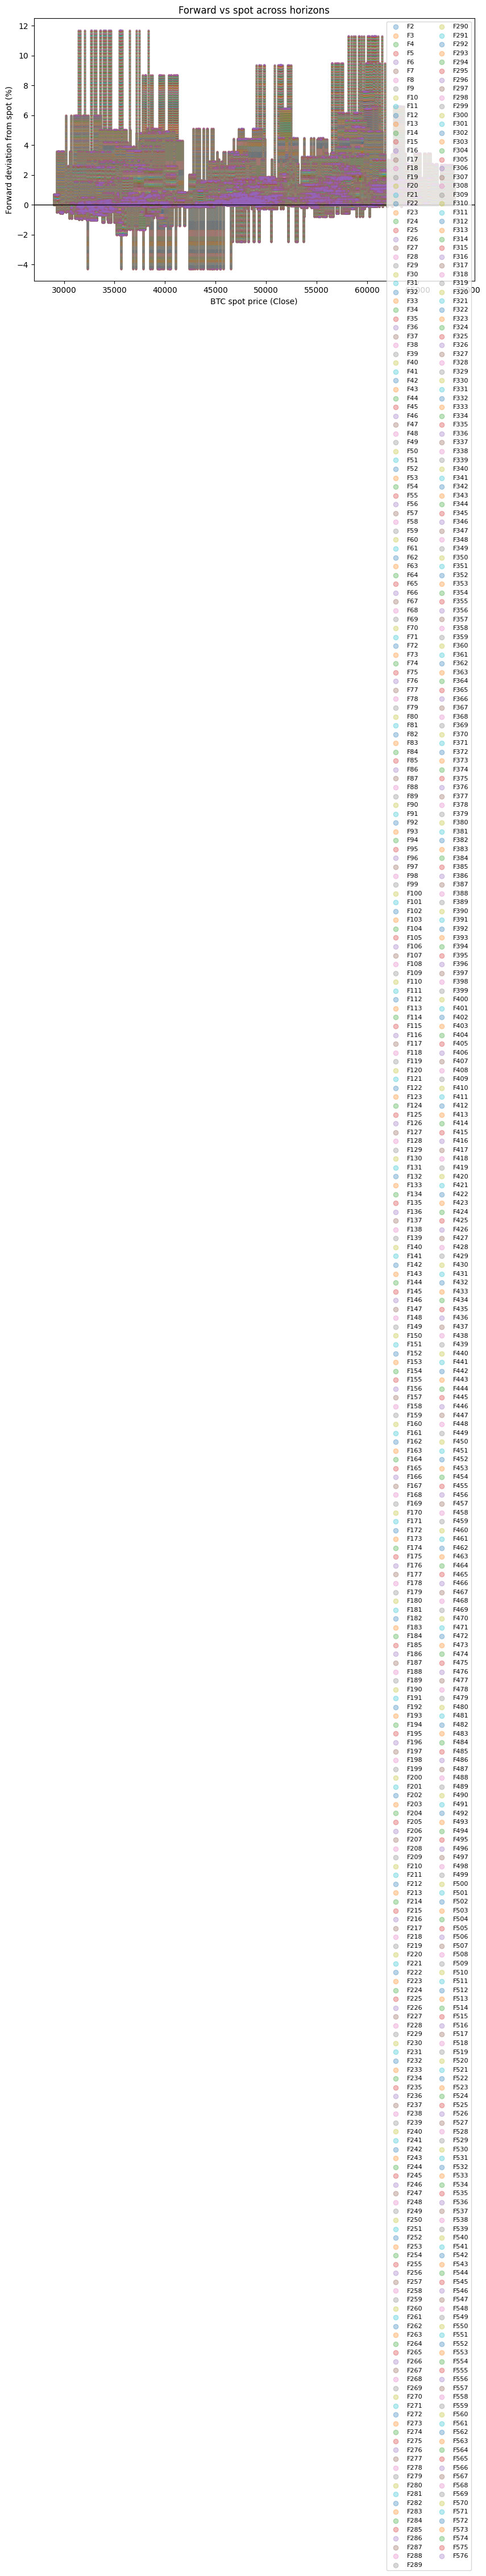

In [10]:
import matplotlib.pyplot as plt

d = d_btc_by_year[y]  # or whichever year/df you're using

# HOURS = [3, 7, 11, 16, 22, 29, 37, 46, 56, 67, 79, 92, 106, 121, 137, 154, 172, 191]
# HOURS = [191, 382, 573, 764] 
# HOURS=[3, 4, 10, 24] # only testing
HOURS = list(range(2, 577))

fig, ax = plt.subplots(figsize=(10, 6))

for H in HOURS:
    pct_dev = (d[f"F{H}"] - d["Close"]) / d["Close"] * 100  # % forward is above/below spot
    ax.scatter(d["Close"], pct_dev, s=4, alpha=0.3, label=f"F{H}")

ax.axhline(0, color="black", linewidth=1)  # 0% = forward equals spot
ax.set_xlabel("BTC spot price (Close)")
ax.set_ylabel("Forward deviation from spot (%)")
ax.set_title("Forward vs spot across horizons")
ax.legend(markerscale=3, fontsize=8, ncol=2)
plt.show()

In [11]:
import os, sys
os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data", exist_ok = True)

In [12]:

import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year_all.pkl", "wb") as f :
    pickle.dump(d_btc_by_year, f)

import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/df_by_year_all.pkl", "wb") as f :
    pickle.dump(df_by_year, f)

- BTC perpetual funding rate, annualized — a rate determined entirely by positioning in the BTC perp market (how much longs pay shorts, or vice versa, every 8 hours on Deribit), reflecting sentiment/leverage imbalance, not any monetary policy or true "risk-free" concept.

In [13]:
### Prepare MFIV with multiple horizons

from srcA.interpol import MFIVPipeline
import numpy as np
import pandas as pd

q = 0.0


# MFIVS = [191, 382, 573, 764] 
MFIVS = list(range(2, 577))

X_by_year = {}
MFIV_by_year = {}

for y in YEARS:
    d_c = d_btc_by_year[y].copy()
    df_c = df_by_year[y].copy()

    idx = ( d_c.index.tz_localize("UTC") if d_c.index.tz is None else d_c.index.tz_convert("UTC") )

    rt = d_c["r"].reindex(idx)

    pipe = MFIVPipeline( df=df_c, d_btc=d_c, q=q )

    pipe.build_surfaces()

    MFIV_byH = pipe.compute_mfiv_byH(H_LIST=MFIVS)
    MFIV_by_year[y] = MFIV_byH

    X_by_year[y] = pd.DataFrame(
        {
            "rt": rt.values
        },
        index=idx
    )
    for H in MFIVS:
        mf = MFIV_byH[H].reindex(idx.tz_convert(None))
        X_by_year[y][f"bsIV_{H}"] = mf["bsIV"].to_numpy()
        X_by_year[y][f"MFIV_{H}"] = mf["MFIV"].to_numpy()

100%|██████████| 6032/6032 [00:02<00:00, 2039.74it/s]
/var/folders/rz/hb914cgn7wb_sxdhbbm8krnh0000gn/T/ipykernel_47954/3072188715.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_by_year[y][f"MFIV_{H}"] = mf["MFIV"].to_numpy()
/var/folders/rz/hb914cgn7wb_sxdhbbm8krnh0000gn/T/ipykernel_47954/3072188715.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_by_year[y][f"bsIV_{H}"] = mf["bsIV"].to_numpy()
/var/folders/rz/hb914cgn7wb_sxdhbbm8krnh0000gn/T/ipykernel_47954/3072188715.py:40: PerformanceWarning: DataFrame is highly

In [14]:
eps = 1e-16

# MFIVS = [191, 382, 573, 764] 
MFIVS = list(range(2, 577))

for y in YEARS:
    for H in MFIVS:
        cols = [f"bsIV_{H}", f"MFIV_{H}"]

        X_by_year[y][cols] = np.exp(
            np.log(
                X_by_year[y][cols].clip(lower=eps)
            ).interpolate(
                method="linear",
                limit_direction="both"
            )
        )

In [ ]:
# # CONVERT TO HOURLY
# YEARS = [2019, 2020, 2021]
# for y in YEARS:
#     X_by_year[y][[f"MFIV_{H}" for H in MFIVS]] /= 8760.0

In [21]:
### COMPUTE AVG MFIV

for y in YEARS:
    # X_by_year[y]["mfiv_avg"] = X_by_year[y][[f"MFIV_{H}" for H in MFIVS]].mean(axis=1)
    X_by_year[y] = pd.concat([
        X_by_year[y], 
        X_by_year[y][[f"MFIV_{H}" for H in MFIVS]].mean(axis=1).to_frame("mfiv_avg")
    ], axis = 1)

In [16]:

os.makedirs("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_all", exist_ok = True)


In [17]:
import pickle
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_all/x_by_year.pkl", "wb") as f:
    pickle.dump(X_by_year, f)

### Load saved X_by_year

In [ ]:
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_all/x_by_year.pkl", "rb") as f:
    X_by_year = pd.read_pickle(f)